# Demo VAG: AWS Textract + OpenAI + FAISS

Pipeline trong một notebook:

PDF local → S3 → Textract async → OCR/layout theo trang → OpenAI Embeddings → FAISS local → retrieve text + ảnh trang → OpenAI trả lời có citation.

> Cảnh báo: AWS hiện không công bố hỗ trợ OCR tiếng Việt cho Textract. Demo này dùng để hiểu kiến trúc và benchmark; không nên mặc định dùng kết quả cho quyết định pháp lý nếu chưa kiểm duyệt.

Textract chỉ thay lớp OCR/layout. Ảnh trang gốc vẫn được đưa vào model vision ở bước cuối, nên đây vẫn là Visual Augmented Generation.

## 1. Cài thư viện

Không ghi API key vào notebook. Boto3 dùng credential chain mặc định: AWS profile, biến môi trường hoặc IAM role.

## 2. Import và cấu hình runtime

Có thể đặt trước các biến: PDF_PATH, AWS_REGION, S3_BUCKET_NAME, OPENAI_API_KEY, OPENAI_VISION_MODEL, OPENAI_EMBEDDING_MODEL, TEXTRACT_MODE.

In [1]:
import base64
import hashlib
import json
import os
import time
from collections import defaultdict
from getpass import getpass
from pathlib import Path

import boto3
import faiss
import fitz
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from botocore.exceptions import ClientError
from dotenv import load_dotenv
from IPython.display import display
from openai import OpenAI
from PIL import Image

load_dotenv()

pdf_value = os.getenv("PDF_PATH") or input("Đường dẫn PDF: ").strip()
bucket_value = os.getenv("S3_BUCKET_NAME") or input("S3 bucket: ").strip()
PDF_PATH = Path(pdf_value).expanduser().resolve()
S3_BUCKET_NAME = bucket_value
AWS_REGION = os.getenv("AWS_REGION") or input("AWS Region: ").strip()
TEXTRACT_MODE = os.getenv("TEXTRACT_MODE", "ANALYSIS").upper()
TEXTRACT_FEATURE_TYPES = [
    value.strip()
    for value in os.getenv("TEXTRACT_FEATURE_TYPES", "LAYOUT,TABLES").split(",")
    if value.strip()
]
OPENAI_VISION_MODEL = os.getenv("OPENAI_VISION_MODEL", "gpt-4.1-mini")
OPENAI_EMBEDDING_MODEL = os.getenv("OPENAI_EMBEDDING_MODEL", "text-embedding-3-small")
ARTIFACT_DIR = Path("artifacts")
PAGE_DIR = ARTIFACT_DIR / "pages"
INDEX_DIR = ARTIFACT_DIR / "faiss"
PAGE_DIR.mkdir(parents=True, exist_ok=True)
INDEX_DIR.mkdir(parents=True, exist_ok=True)

if not PDF_PATH.is_file():
    raise FileNotFoundError(PDF_PATH)
if PDF_PATH.suffix.lower() != ".pdf":
    raise ValueError("Demo này yêu cầu file PDF.")
if TEXTRACT_MODE not in {"ANALYSIS", "TEXT_DETECTION"}:
    raise ValueError("TEXTRACT_MODE phải là ANALYSIS hoặc TEXT_DETECTION.")
if not os.getenv("OPENAI_API_KEY"):
    os.environ["OPENAI_API_KEY"] = getpass("OpenAI API key: ")

print({
    "pdf": PDF_PATH.name,
    "bucket": S3_BUCKET_NAME,
    "region": AWS_REGION,
    "textract_mode": TEXTRACT_MODE,
    "features": TEXTRACT_FEATURE_TYPES,
})

FileNotFoundError: /absolute/path/to/document.pdf

## 3. Khởi tạo clients và kiểm tra AWS identity

Không truyền access key trực tiếp vào boto3. Trên ECS/EC2, SDK sẽ dùng IAM role của workload.

In [2]:
session = boto3.Session(region_name=AWS_REGION)
s3 = session.client("s3")
textract = session.client("textract")
sts = session.client("sts")
openai_client = OpenAI()

identity = sts.get_caller_identity()
print("AWS account:", identity["Account"])
print("AWS principal:", identity["Arn"])

AWS account: 529745008569
AWS principal: arn:aws:iam::529745008569:user/documind-user-new


## 4. Upload PDF lên S3

Object key dùng SHA-256 để chạy lại notebook không tạo nhiều bản sao.

In [3]:
def sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

document_hash = sha256_file(PDF_PATH)
S3_KEY = f"textract-vag-demo/{document_hash}/raw/{PDF_PATH.name}"

try:
    s3.head_object(Bucket=S3_BUCKET_NAME, Key=S3_KEY)
    print("Đã có trên S3:", S3_KEY)
except ClientError as exc:
    status_code = exc.response.get("ResponseMetadata", {}).get("HTTPStatusCode")
    if status_code != 404:
        raise
    s3.upload_file(
        str(PDF_PATH),
        S3_BUCKET_NAME,
        S3_KEY,
        ExtraArgs={"ContentType": "application/pdf", "ServerSideEncryption": "AES256"},
    )
    print("Đã upload:", S3_KEY)

Đã có trên S3: textract-vag-demo/db7d4963de2bb46707460d841e65c6c6b06650cc28952321c0c85d1b9281e3c2/raw/Nghi_dinh_130_2025.pdf


## 5. Gửi Textract job bất đồng bộ

- TEXT_DETECTION: chỉ OCR dòng/từ.
- ANALYSIS: thêm layout/bảng theo FeatureTypes.

Production nên nhận trạng thái qua SNS/SQS. Polling dưới đây chỉ phù hợp notebook demo.

In [4]:
document_location = {"S3Object": {"Bucket": S3_BUCKET_NAME, "Name": S3_KEY}}
request_token = document_hash[:64]

if TEXTRACT_MODE == "ANALYSIS":
    started = textract.start_document_analysis(
        DocumentLocation=document_location,
        FeatureTypes=TEXTRACT_FEATURE_TYPES,
        ClientRequestToken=request_token,
        JobTag="textract-vag-demo",
    )
    get_result = textract.get_document_analysis
else:
    started = textract.start_document_text_detection(
        DocumentLocation=document_location,
        ClientRequestToken=request_token,
        JobTag="textract-vag-demo",
    )
    get_result = textract.get_document_text_detection

JOB_ID = started["JobId"]
print("Textract JobId:", JOB_ID)

Textract JobId: cae8e6981e9ccc25b9725dada8bf5f3cd7883c80dd3ee6b80a12681de1a36370


In [5]:
def wait_for_textract(job_id: str, timeout_seconds: int = 900) -> dict:
    started_at = time.monotonic()
    delay = 2.0
    while True:
        response = get_result(JobId=job_id, MaxResults=1)
        job_status = response["JobStatus"]
        print("Textract status:", job_status)
        if job_status in {"SUCCEEDED", "PARTIAL_SUCCESS"}:
            return response
        if job_status == "FAILED":
            raise RuntimeError(response.get("StatusMessage", "Textract job failed"))
        if time.monotonic() - started_at > timeout_seconds:
            raise TimeoutError(f"Textract chưa hoàn tất sau {timeout_seconds} giây")
        time.sleep(delay)
        delay = min(delay * 1.5, 15)

first_result = wait_for_textract(JOB_ID)

Textract status: IN_PROGRESS
Textract status: IN_PROGRESS
Textract status: SUCCEEDED


## 6. Tải toàn bộ kết quả Textract

GetDocumentAnalysis và GetDocumentTextDetection phân trang bằng NextToken; không được chỉ lấy response đầu tiên.

In [6]:
def fetch_all_blocks(job_id: str) -> tuple[list[dict], dict]:
    blocks = []
    document_metadata = {}
    next_token = None
    while True:
        params = {"JobId": job_id, "MaxResults": 1000}
        if next_token:
            params["NextToken"] = next_token
        response = get_result(**params)
        if response["JobStatus"] not in {"SUCCEEDED", "PARTIAL_SUCCESS"}:
            raise RuntimeError(response.get("StatusMessage", response["JobStatus"]))
        blocks.extend(response.get("Blocks", []))
        document_metadata = response.get("DocumentMetadata", document_metadata)
        next_token = response.get("NextToken")
        if not next_token:
            break
    return blocks, document_metadata

blocks, textract_metadata = fetch_all_blocks(JOB_ID)
print("Số trang:", textract_metadata.get("Pages"))
print("Tổng blocks:", len(blocks))
pd.Series([block["BlockType"] for block in blocks]).value_counts()

Số trang: 4
Tổng blocks: 1547


WORD                     1345
LINE                      131
LAYOUT_TEXT                44
LAYOUT_HEADER               7
LAYOUT_LIST                 6
PAGE                        4
LAYOUT_SECTION_HEADER       4
LAYOUT_PAGE_NUMBER          3
LAYOUT_FIGURE               2
LAYOUT_TITLE                1
Name: count, dtype: int64

## 7. Chuẩn hoá OCR theo trang

Dòng được sắp theo vị trí Top rồi Left. Confidence được giữ lại để đánh dấu trang OCR kém.

In [7]:
def normalize_textract_pages(raw_blocks: list[dict]) -> list[dict]:
    grouped = defaultdict(list)
    for block in raw_blocks:
        if block.get("BlockType") != "LINE":
            continue
        box = block.get("Geometry", {}).get("BoundingBox", {})
        grouped[int(block.get("Page", 1))].append({
            "text": block.get("Text", ""),
            "confidence": float(block.get("Confidence", 0)),
            "top": float(box.get("Top", 0)),
            "left": float(box.get("Left", 0)),
        })

    pages = []
    for page_number in sorted(grouped):
        lines = sorted(grouped[page_number], key=lambda item: (item["top"], item["left"]))
        mean_confidence = np.mean([line["confidence"] for line in lines]) if lines else 0.0
        pages.append({
            "page_number": page_number,
            "text": "\n".join(line["text"] for line in lines),
            "mean_confidence": float(mean_confidence),
            "lines": lines,
        })
    return pages

pages = normalize_textract_pages(blocks)
ocr_report = pd.DataFrame([
    {
        "page": page["page_number"],
        "characters": len(page["text"]),
        "lines": len(page["lines"]),
        "mean_confidence": round(page["mean_confidence"], 2),
    }
    for page in pages
])
display(ocr_report.head(20))
print("\nOCR trang đầu:\n")
print(pages[0]["text"][:3000])

,page,characters,lines,mean_confidence
0,1,1421,37,82.06
1,2,1915,31,83.88
2,3,1937,32,87.36
3,4,977,31,82.88



OCR trang đầu:

Nguòi ký: CÔNG THÔNG TIN DIEN TÚ CHÍNH PHU
VGP
Email: thongtinchinhphu@chinhphu.yn
Co quan: VAN PHONG CHINH PHU
TTDT(2)
CHINHPHU. / NThòi gian kv: 13.06.2025 08:51:39 +07:00
CONG HÒA XÃ HOI CHU NGHIA VIET NAM
CHÍNH PHÙ
Dôc lâp - Ty do - Hanh phúc
Hà Nôi, ngày 11 tháng 6 nãm 2025
Só: 130/2025/ND-CP
CONG THONG TIN DIEN TÚ CHINH PHU
S
DEN
CiV:
Ngey: 13 13/6/2025
NGHI DINH
Quy dinh vè phân quyèn, phân câp trong linh vurc thông kê
Can cú Luât Tô chúc Chinh phù nãm 2025;
Căn cúr Luât Tô chúc chinh quyên dia phuong năm 2025;
Căn cú Nghi quyét só 190/2025/QH15 ngày 19 tháng 02 năm 2025 cúa
Quóc hôi quy dinh vè xie ly môt só vân dè liên quan dén sap xép tó chúc bô máy
nhà nuóc;
Theo dè nghi cúa Bô truong Bô Tài chính;
Chinh phù ban hành Nghi dinh quy dinh vê phân quyên, phân cap trong
lînh vuc thong kê.
Diêu 1. Pham vi dièu chinh
Nghi dinh này quy dinh thâm quyèn trong lînh vuc thông kê duoc quy
dinh tai luât, nghi dinh cúa Chinh phù cân diêu chinh dè thuc hiên phân
quyên, phân

## 8. Render PDF thành ảnh trang

Textract trả text và toạ độ. VAG vẫn giữ ảnh để model kiểm chứng dấu, bảng, chữ ký và bố cục khi trả lời.

Đã render 4 trang vào /Users/vietannguyen/TechX_projects/genai_business/22. AWS Textract/artifacts/pages


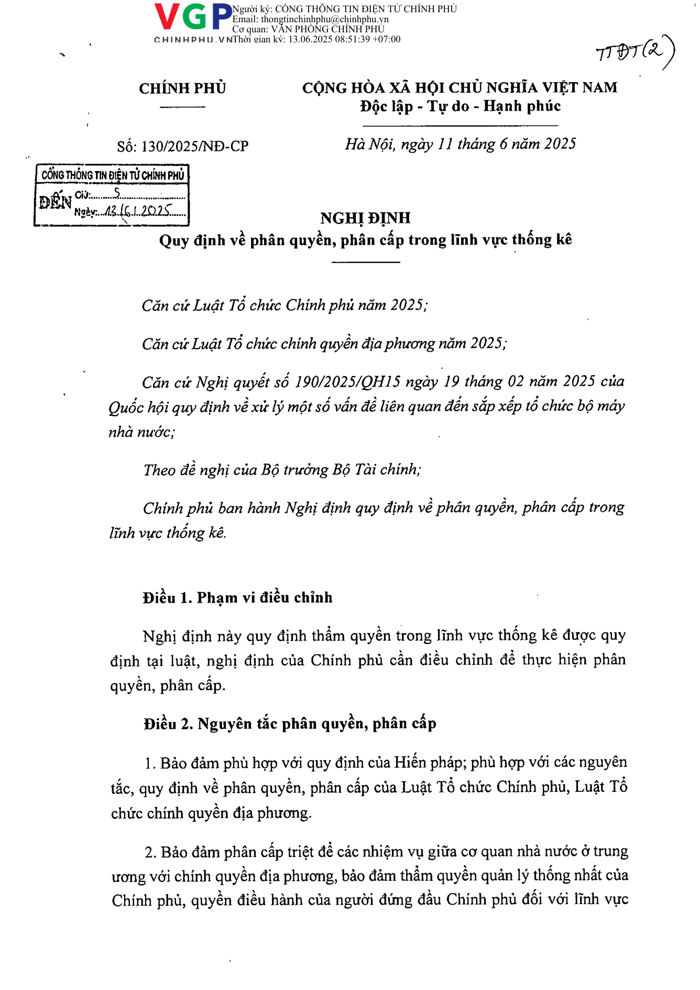

In [8]:
def render_pdf(path: Path, output_dir: Path, dpi: int = 160) -> dict[int, Path]:
    rendered = {}
    matrix = fitz.Matrix(dpi / 72, dpi / 72)
    with fitz.open(path) as document:
        for page_number, page in enumerate(document, start=1):
            output = output_dir / f"page-{page_number:04d}.png"
            if not output.exists():
                page.get_pixmap(matrix=matrix, alpha=False).save(output)
            rendered[page_number] = output
    return rendered

page_images = render_pdf(PDF_PATH, PAGE_DIR)
print(f"Đã render {len(page_images)} trang vào {PAGE_DIR.resolve()}")
display(Image.open(page_images[1]).resize((700, 990)))

## 9. Chunk theo trang

Không trộn nội dung từ hai trang vào cùng chunk để citation và ảnh nguồn luôn xác định được.

In [9]:
def chunk_text(text: str, max_chars: int = 3000, overlap: int = 300) -> list[str]:
    cleaned = "\n".join(line.strip() for line in text.splitlines() if line.strip())
    if not cleaned:
        return []
    result = []
    start = 0
    while start < len(cleaned):
        end = min(start + max_chars, len(cleaned))
        if end < len(cleaned):
            boundary = cleaned.rfind("\n", start, end)
            if boundary > start + max_chars // 2:
                end = boundary
        result.append(cleaned[start:end].strip())
        if end >= len(cleaned):
            break
        start = max(end - overlap, start + 1)
    return result

chunks = []
for page in pages:
    for chunk_index, text in enumerate(chunk_text(page["text"]), start=1):
        chunks.append({
            "id": f"{document_hash}:p{page['page_number']}:c{chunk_index}",
            "document": PDF_PATH.name,
            "page_number": page["page_number"],
            "chunk_index": chunk_index,
            "text": text,
            "ocr_confidence": page["mean_confidence"],
            "image_path": str(page_images[page["page_number"]].resolve()),
        })

print("Tổng chunks:", len(chunks))
display(pd.DataFrame(chunks)[["page_number", "chunk_index", "ocr_confidence"]].head())

Tổng chunks: 4


,page_number,chunk_index,ocr_confidence
0,1,1,82.061467
1,2,1,83.884288
2,3,1,87.361821
3,4,1,82.876947


## 10. OpenAI embeddings và FAISS local

FAISS dùng cosine similarity bằng cách chuẩn hoá vector rồi tìm inner product. Index và metadata được lưu cục bộ.

In [10]:
def embed_texts(texts: list[str], batch_size: int = 64) -> np.ndarray:
    vectors = []
    for start in range(0, len(texts), batch_size):
        response = openai_client.embeddings.create(
            model=OPENAI_EMBEDDING_MODEL,
            input=texts[start:start + batch_size],
        )
        vectors.extend(item.embedding for item in response.data)
    matrix = np.asarray(vectors, dtype="float32")
    faiss.normalize_L2(matrix)
    return matrix

if not chunks:
    raise RuntimeError("Textract không trích xuất được text để tạo index.")

embedding_matrix = embed_texts([chunk["text"] for chunk in chunks])
index = faiss.IndexFlatIP(embedding_matrix.shape[1])
index.add(embedding_matrix)
faiss.write_index(index, str(INDEX_DIR / "textract_vag.index"))
(INDEX_DIR / "metadata.json").write_text(
    json.dumps(chunks, ensure_ascii=False, indent=2),
    encoding="utf-8",
)
print("FAISS vectors:", index.ntotal, "dimension:", index.d)

FAISS vectors: 4 dimension: 1536


## 11. Retrieve chunks liên quan

In [11]:
def retrieve(question: str, top_k: int = 6) -> list[dict]:
    query_vector = embed_texts([question])
    scores, positions = index.search(query_vector, min(top_k, index.ntotal))
    results = []
    for score, position in zip(scores[0], positions[0]):
        item = dict(chunks[int(position)])
        item["score"] = float(score)
        results.append(item)
    return results

QUESTION = os.getenv(
    "QUESTION",
    "Văn bản quy định những nội dung chính nào và căn cứ nằm ở trang nào?",
)
retrieved = retrieve(QUESTION)
display(pd.DataFrame(retrieved)[["page_number", "chunk_index", "score", "ocr_confidence"]])

,page_number,chunk_index,score,ocr_confidence
0,4,1,0.384015,82.876947
1,1,1,0.371581,82.061467
2,3,1,0.352513,87.361821
3,2,1,0.325109,83.884288


## 12. Visual grounding: trả lời từ OCR và ảnh trang

Model nhận cả context Textract và ảnh những trang FAISS truy hồi. Prompt yêu cầu không tự suy diễn khi OCR hoặc ảnh không đủ rõ.

In [12]:
def image_data_url(path: Path) -> str:
    encoded = base64.b64encode(path.read_bytes()).decode("ascii")
    return f"data:image/png;base64,{encoded}"

def answer_with_visual_grounding(question: str, retrieved_chunks: list[dict]) -> str:
    context = "\n\n".join(
        f"[Trang {item['page_number']} | OCR confidence {item['ocr_confidence']:.1f}]\n{item['text']}"
        for item in retrieved_chunks
    )
    content = [{
        "type": "input_text",
        "text": (
            "Bạn là trợ lý nghiên cứu văn bản pháp lý. Chỉ trả lời từ context OCR và ảnh nguồn. "
            "Ưu tiên ảnh khi OCR sai dấu hoặc sai bố cục. Mỗi nhận định phải ghi [Trang N]. "
            "Nếu không đủ căn cứ, nói rõ điểm chưa chắc chắn. Không khẳng định trạng thái hiệu lực.\n\n"
            f"Câu hỏi: {question}\n\nContext Textract:\n{context}"
        ),
    }]

    selected_pages = []
    for item in retrieved_chunks:
        page_number = item["page_number"]
        if page_number not in selected_pages:
            selected_pages.append(page_number)
        if len(selected_pages) == 4:
            break

    for page_number in selected_pages:
        content.append({"type": "input_text", "text": f"Ảnh nguồn trang {page_number}:"})
        content.append({
            "type": "input_image",
            "image_url": image_data_url(page_images[page_number]),
            "detail": "high",
        })

    response = openai_client.responses.create(
        model=OPENAI_VISION_MODEL,
        input=[{"role": "user", "content": content}],
        store=False,
    )
    return response.output_text

answer = answer_with_visual_grounding(QUESTION, retrieved)
print(answer)

Văn bản quy định những nội dung chính sau:

1. Phạm vi điều chỉnh (Trang 1): Quy định thẩm quyền trong lĩnh vực thống kê được quy định tại luật, nghị định của Chính phủ cần điều chỉnh để thực hiện phân quyền, phân cấp.

2. Nguyên tắc phân quyền, phân cấp (Trang 1-2):
   - Bảo đảm phù hợp với Hiến pháp và các luật về tổ chức Chính phủ, chính quyền địa phương.
   - Phân cấp triệt để nhiệm vụ giữa cơ quan nhà nước trung ương và chính quyền địa phương, đảm bảo thẩm quyền quản lý thống nhất của Chính phủ.
   - Tập trung thực hiện nhiệm vụ quản lý nhà nước ở tầm vĩ mô, xây dựng thể chế, chiến lược, kế hoạch đồng bộ.
   - Đẩy mạnh phân quyền, phân cấp và phân định rõ thẩm quyền giữa các cấp chính quyền địa phương.
   - Thực hiện phân quyền, phân cấp giữa các ngành, lĩnh vực liên quan để bảo đảm đồng bộ, thống nhất.
   - Bảo đảm quyền con người, quyền công dân; công khai, minh bạch; không ảnh hưởng đến hoạt động bình thường xã hội, người dân, doanh nghiệp.
   - Bảo đảm không ảnh hưởng đến việc

## 13. Xem ảnh nguồn đã dùng

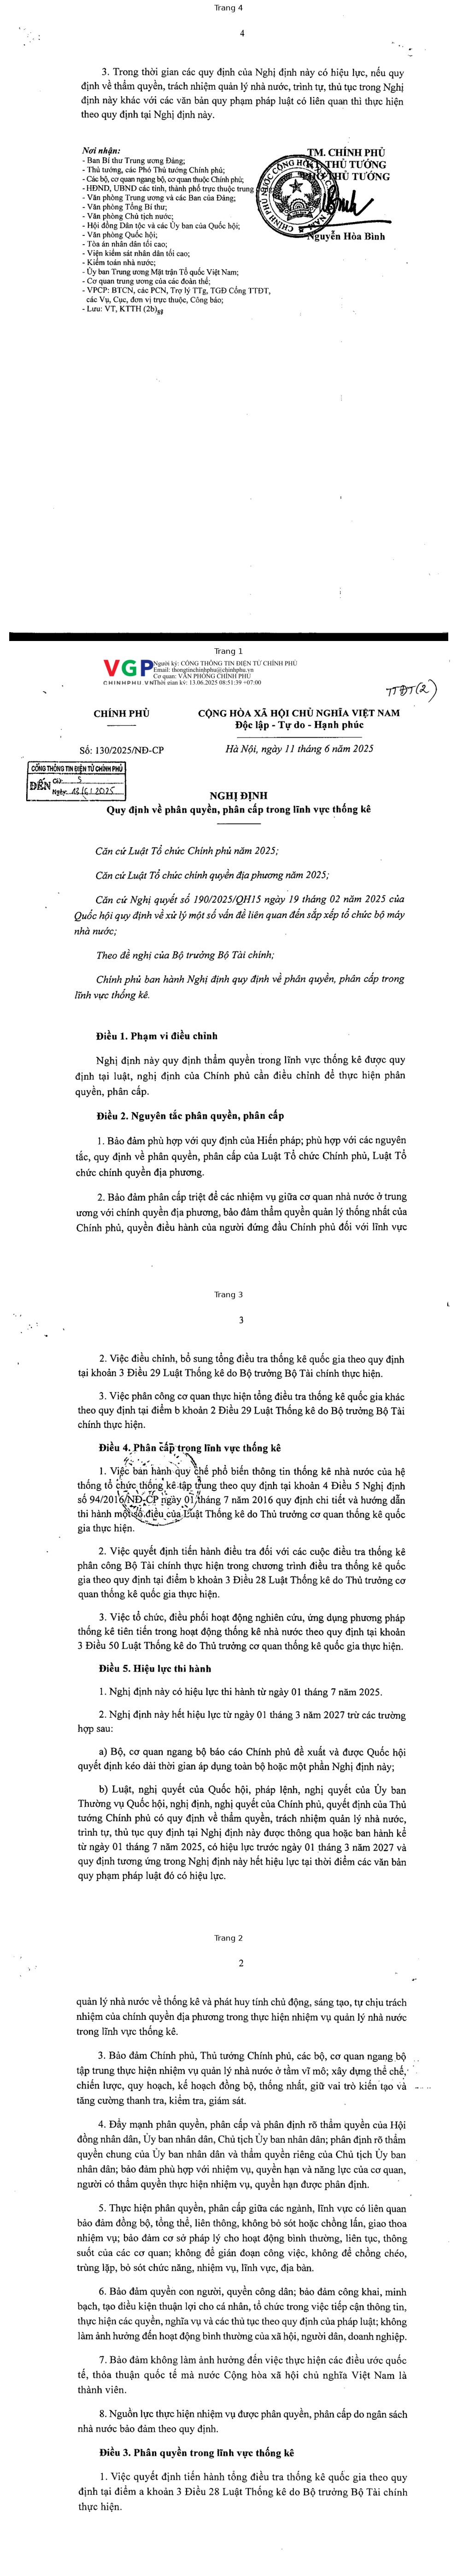

In [13]:
source_pages = list(dict.fromkeys(item["page_number"] for item in retrieved))[:4]
figure, axes = plt.subplots(len(source_pages), 1, figsize=(12, 14 * len(source_pages)))
axes = np.atleast_1d(axes)
for axis, page_number in zip(axes, source_pages):
    axis.imshow(Image.open(page_images[page_number]))
    axis.set_title(f"Trang {page_number}")
    axis.axis("off")
plt.tight_layout()

## 14. Đánh giá trước production

Tài liệu chính thức:

- AWS Textract async: https://docs.aws.amazon.com/textract/latest/dg/api-async.html
- AWS Textract limits/languages: https://docs.aws.amazon.com/textract/latest/dg/limits-document.html
- OpenAI image inputs: https://developers.openai.com/api/docs/guides/images-vision
- OpenAI embeddings: https://developers.openai.com/api/docs/guides/embeddings